In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (7043, 21)


In [6]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [7]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [8]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [11]:
print("Blank strings in TotalCharges:",
      (df["TotalCharges"].str.strip() == "").sum())

print("\nFirst 10 TotalCharges values:")
print(df["TotalCharges"].head(10).tolist())

Blank strings in TotalCharges: 11

First 10 TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']


In [12]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Data type:", df["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

Data type: float64
Missing values in TotalCharges: 11


In [13]:
df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Missing TotalCharges values: 0
TotalCharges data type: float64


In [15]:
df = df.drop("customerID", axis=1)

print("Dataset shape:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Dataset shape: (7043, 20)

Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
print("Churn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


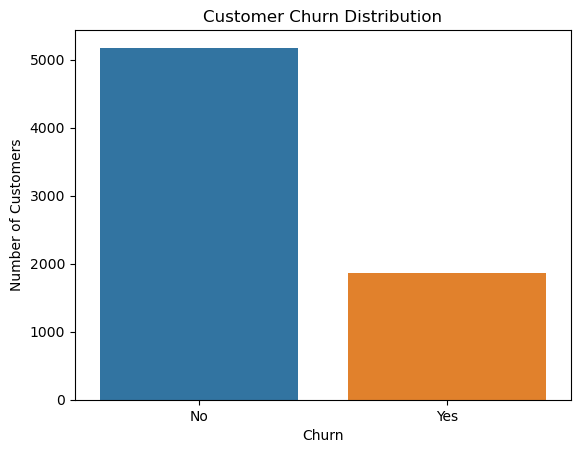

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn", hue="Churn", legend=False)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

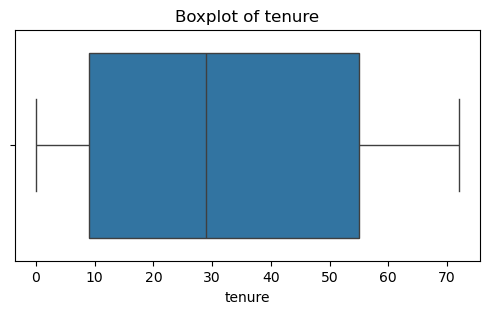

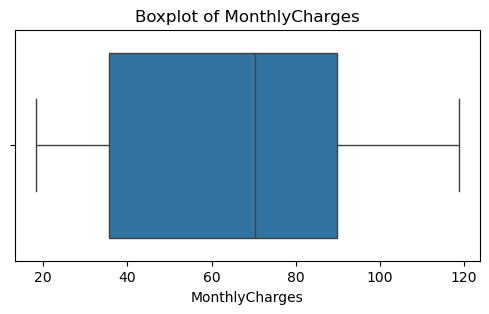

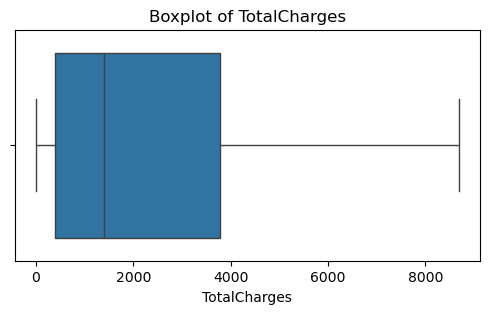

In [18]:
numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for column in numerical_columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.show()

In [19]:
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [20]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [21]:
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Encode the target variable
y_encoded = y.map({"No": 0, "Yes": 1})

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

print("\nFirst 5 rows of encoded features:")
print(X_encoded.head())

print("\nEncoded target values:")
print(y_encoded.value_counts())

Original feature shape: (7043, 19)
Encoded feature shape: (7043, 30)

First 5 rows of encoded features:
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85            0   
1              0      34           56.95       1889.50            1   
2              0       2           53.85        108.15            1   
3              0      45           42.30       1840.75            1   
4              0       2           70.70        151.65            0   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0            1               0                 0   
1            0               0                 1   
2            0               0                 1   
3            0               0                 0   
4            0               0                 1   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                               1                  0  ...   
1                               0 

In [24]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nChurn distribution in training data:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nChurn distribution in testing data:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features shape: (5634, 30)
Testing features shape: (1409, 30)

Training target shape: (5634,)
Testing target shape: (1409,)

Churn distribution in training data:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Churn distribution in testing data:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [25]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (5634, 30)
Scaled testing data shape: (1409, 30)


In [26]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")
print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10].tolist())

Logistic Regression model trained successfully!
First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted values:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]


Logistic Regression Evaluation
--------------------------------
Accuracy: 0.807
Precision: 0.6584
Recall: 0.5668
F1-score: 0.6092

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[925 110]
 [162 212]]


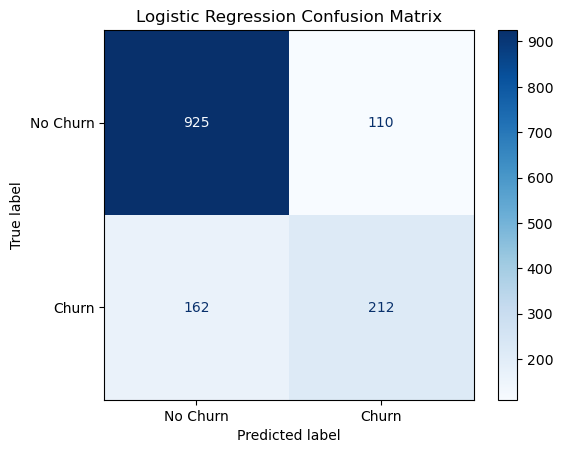

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_lr, 4))
print("Precision:", round(precision_lr, 4))
print("Recall:", round(recall_lr, 4))
print("F1-score:", round(f1_lr, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [28]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree model trained successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10].tolist())

Decision Tree model trained successfully!

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted values:
[0, 1, 0, 1, 0, 0, 0, 0, 0, 0]


Decision Tree Evaluation
------------------------
Accuracy: 0.726
Precision: 0.4838
Recall: 0.4786
F1-score: 0.4812

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.82      0.81      1035
           1       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409

Confusion Matrix:
[[844 191]
 [195 179]]


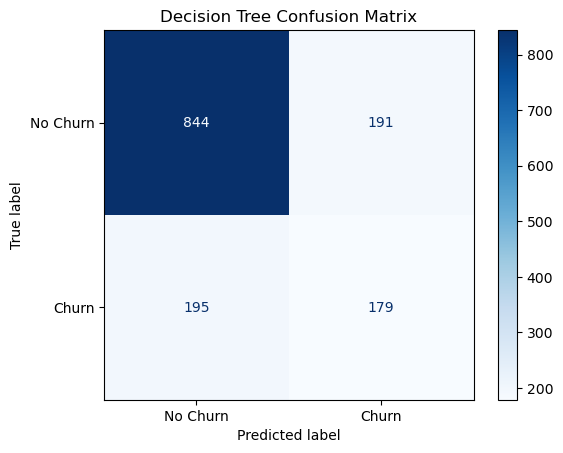

In [29]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Decision Tree Evaluation")
print("------------------------")
print("Accuracy:", round(accuracy_dt, 4))
print("Precision:", round(precision_dt, 4))
print("Recall:", round(recall_dt, 4))
print("F1-score:", round(f1_dt, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10].tolist())

Random Forest model trained successfully!

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted values:
[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]


Random Forest Evaluation
------------------------
Accuracy: 0.785
Precision: 0.6179
Recall: 0.4973
F1-score: 0.5511

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.50      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409

Confusion Matrix:
[[920 115]
 [188 186]]


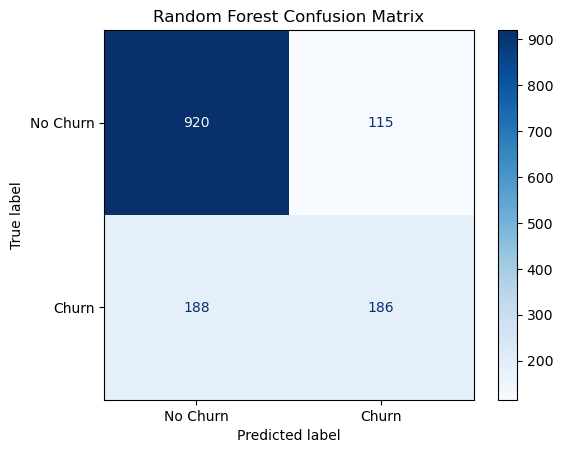

In [31]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [32]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision_lr,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall_lr,
        recall_dt,
        recall_rf
    ],
    "F1-score": [
        f1_lr,
        f1_dt,
        f1_rf
    ]
})

print("Model Performance Comparison:")
print(results.round(4).to_string(index=False))

Model Performance Comparison:
              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression     0.807     0.6584  0.5668    0.6092
      Decision Tree     0.726     0.4838  0.4786    0.4812
      Random Forest     0.785     0.6179  0.4973    0.5511


Top 10 Important Features:
                       Feature  Importance
                  TotalCharges    0.191149
                        tenure    0.174795
                MonthlyCharges    0.169026
PaymentMethod_Electronic check    0.039095
   InternetService_Fiber optic    0.037259
             Contract_Two year    0.029864
            OnlineSecurity_Yes    0.029774
                   gender_Male    0.028501
          PaperlessBilling_Yes    0.025097
               TechSupport_Yes    0.023192


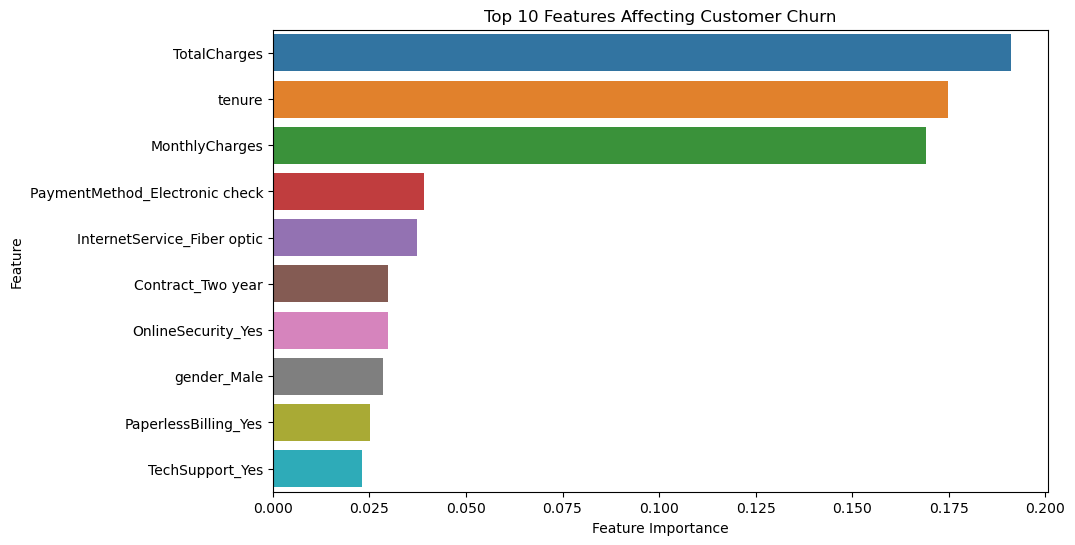

In [33]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False
)

plt.title("Top 10 Features Affecting Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

### Business Conclusion

The customer churn prediction project was completed using Logistic Regression, Decision Tree, and Random Forest classification algorithms. Among the three models, Logistic Regression performed best, achieving an accuracy of **80.70%** and an F1-score of **60.92%**. The feature importance analysis identified TotalCharges, tenure, and MonthlyCharges as the three most important predictive features.

The telecommunications company can use these findings to identify customers who may be at risk of leaving and develop targeted retention strategies, such as personalized offers, contract incentives, and improved customer support. However, further improvement in churn detection is needed because the best model identified only 56.68% of actual churners.
